In [31]:
#Practica 2_ Realizado por Angel Antolin
import pandas as pd
import numpy as np
from sklearn.tree import DecisionTreeClassifier, export_graphviz
import graphviz

In [32]:
tabla = []

#Columnas de la A a la J, letras de la funcion
columnas = [chr(65 + i) for i in range(10)]

#Recorrer todas las posibiliades para generar todos los valores de bits
for i in range(2**10):

    #Convertir i a binario, borrar el prefijo 0b que pone bin y llenar con 0 a la izquierda
    binario = bin(i)[2:].zfill(10)
    
    fila = {}

    #Uso zip para unir cada letra con el bit en su posicion y guardo en un diccionario
    #la letra con True, si era 1 o False si es 0
    for letra, bit in zip(columnas, binario):

        fila[letra] = (bit == '1')

    #Guardar en variables cada valor de la fila
    A, B, C, D, E, F, G, H, I, J = fila.values()

    #Evaluar la funcion
    termino1 = (A & B) | ((not C) & D)
    termino2 = (E | (not F))
    termino3 = (G | H | I | J)
    fila['Resultado'] = termino1 ^ (termino2 & termino3)
    
    #Guardar el resultado de la funcion en la tabla que construira el arbol
    tabla.append(fila)


#Convertir la tabla en DataFrame para poder mostrarla y pasarlo a enteros para usarlo en weka
df = pd.DataFrame(tabla)
df_enteros = df.astype(int)
df_enteros.to_csv('funcion_logica_entrega.csv', index = False)



                 

In [33]:
#Generar el arbol

X = df_enteros[columnas]
Y = df_enteros['Resultado']


arbol = DecisionTreeClassifier(
    criterion='entropy', #Similar a ID3
    min_samples_leaf = 1, #MinNumOBj = 1
    ccp_alpha = 0.0,  #Unprunned = True
    max_depth = None)  #collapseTree = False

arbol.fit(X, Y)


,criterion,'entropy'
,splitter,'best'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,None
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


In [34]:
#Precision del arbol
acc = arbol.score(X,Y)
acc

1.0

In [35]:
#Mostrar Grafico
export_graphviz(arbol, 
                out_file='tree_funcion_SKLEARN.dot', 
                feature_names= X.columns,
                class_names = ['Falso', 'Verdadero'])

!dot -Tpng tree_funcion_SKLEARN.dot -o tree_funcion_SKLEARN.png -Gdpi=300


# ** ARBOL GENERADO POR SKLEARN **
![Arbol_FUNCION](./tree_funcion_SKLEARN.png)

# ** ARBOL GENERADO POR ID3_J48 ** 

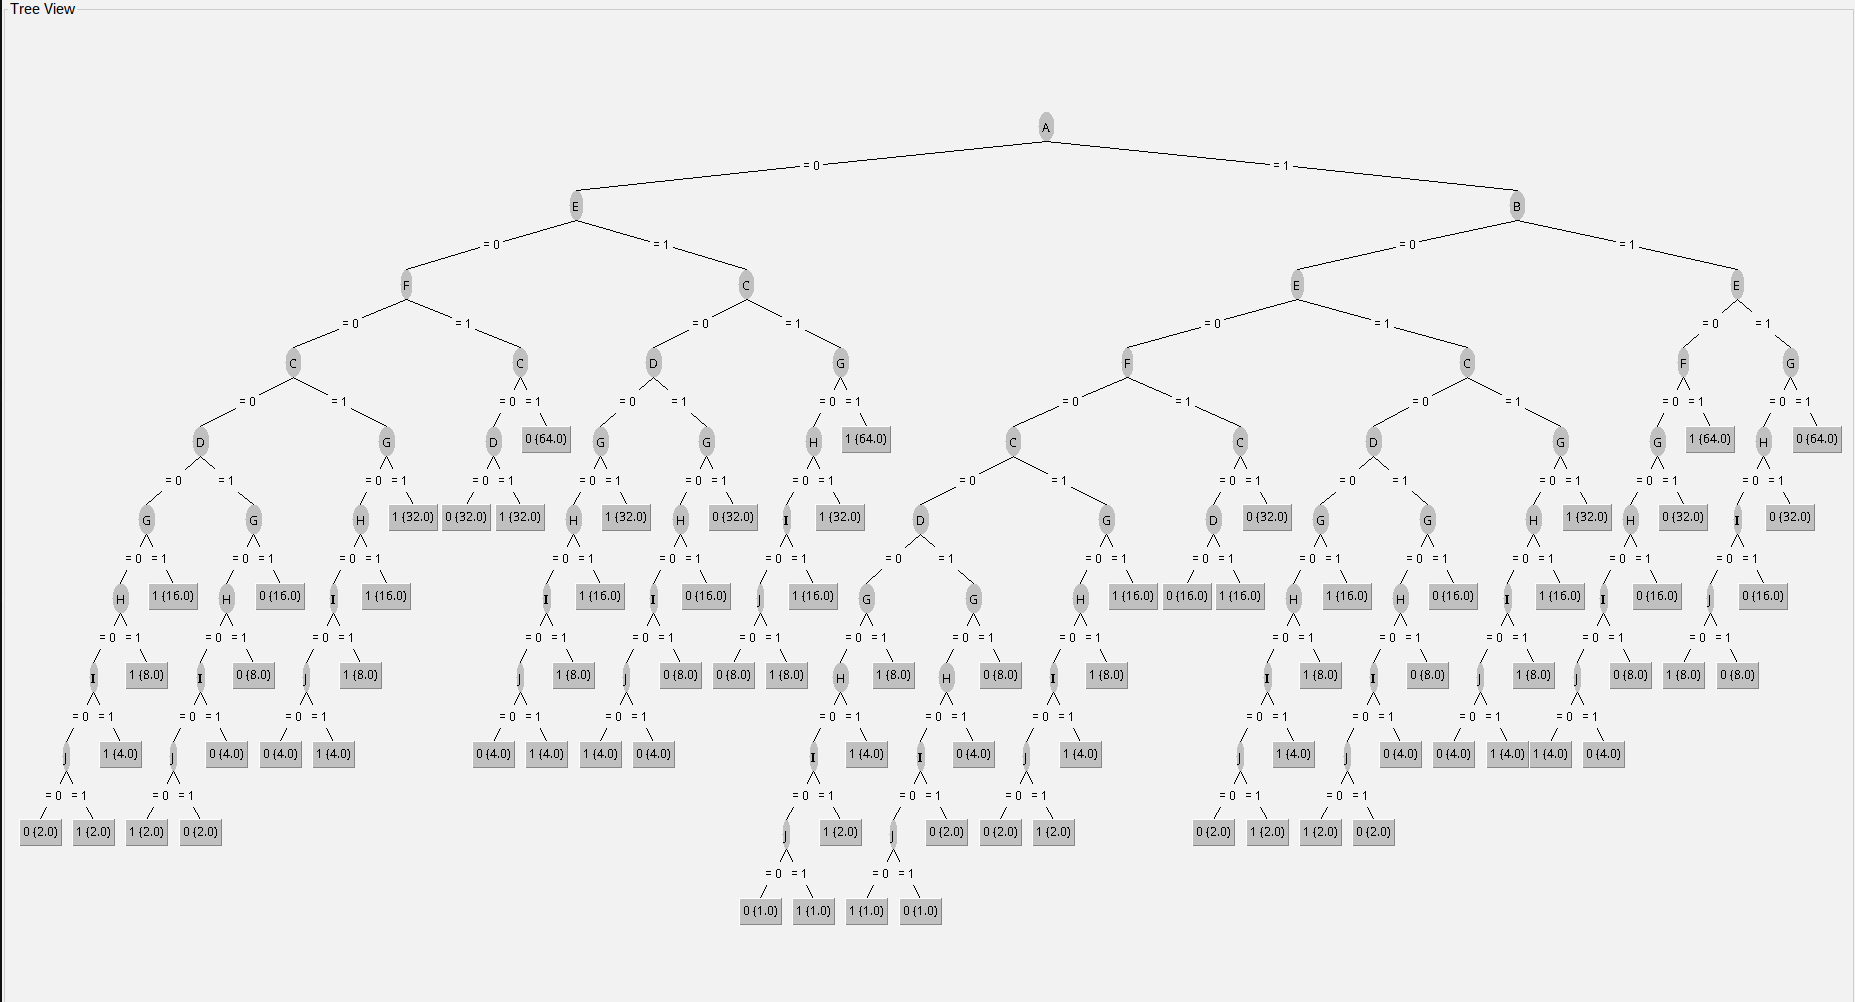